In [ ]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "dynamic_pipeline_builder.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
FIG = ROOT / "artifacts" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

## 1. Завантаження і типи колонок

In [ ]:
clean = pd.read_csv(ROOT / "data/processed/german_credit_clean.csv")
mcar = pd.read_csv(ROOT / "data/processed/german_credit_mcar.csv")  
print(clean.shape)
clean.dtypes.to_frame("dtype").T

(1000, 22)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,sex,bad_credit
dtype,str,int64,str,str,int64,str,str,int64,str,str,int64,str,int64,str,str,int64,str,int64,str,str,str,int64


## 2. Частки пропусків (повний набір, лише для EDA)


In [3]:
shares = mcar.isna().sum().div(len(mcar)).rename("missing_share")
shares[shares > 0].sort_values().to_frame()

,missing_share
job,0.03
age,0.05
savings_account,0.06
employment_since,0.15
credit_amount,0.20
purpose,0.25
residence_since,0.50


## 3. Описова статистика числових ознак і викиди

In [4]:
numeric = ["duration", "credit_amount", "age", "installment_rate", "residence_since",
           "existing_credits", "num_dependents"]
desc = clean[numeric].describe().T
desc["skew"] = clean[numeric].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,1.09
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0,-0.53
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0,-0.27
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.27
num_dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.91


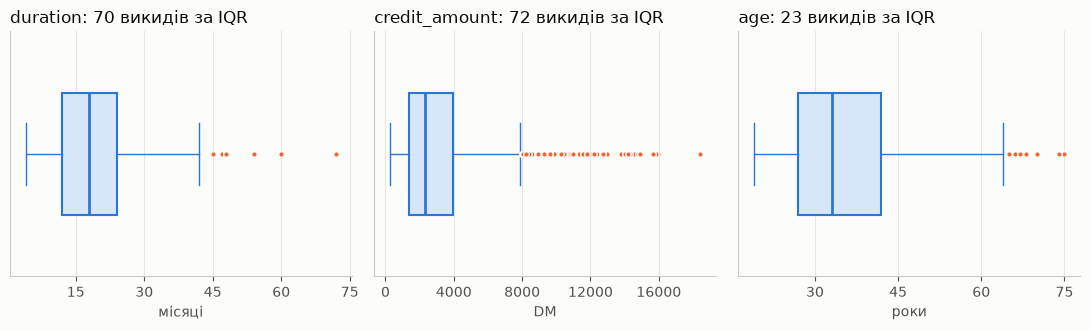

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, unit in zip(axes, ["duration", "credit_amount", "age"], ["місяці", "DM", "роки"]):
    ax.boxplot(clean[col], orientation="horizontal", widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#d7e6f8", edgecolor=BLUE, linewidth=1.5),
               medianprops=dict(color=BLUE, linewidth=2), whiskerprops=dict(color=BLUE),
               capprops=dict(color=BLUE), flierprops=dict(marker="o", markersize=4,
               markerfacecolor=ORANGE, markeredgecolor="#fcfcfb"))
    q1, q3 = clean[col].quantile([0.25, 0.75])
    n_out = int((clean[col] > q3 + 1.5 * (q3 - q1)).sum())
    ax.set_title(f"{col}: {n_out} викидів за IQR", loc="left")
    ax.set_xlabel(unit); ax.set_yticks([]); ax.xaxis.set_major_locator(plt.MaxNLocator(5))
fig.tight_layout(); fig.savefig(FIG / "eda_outliers.png", dpi=130); plt.show()

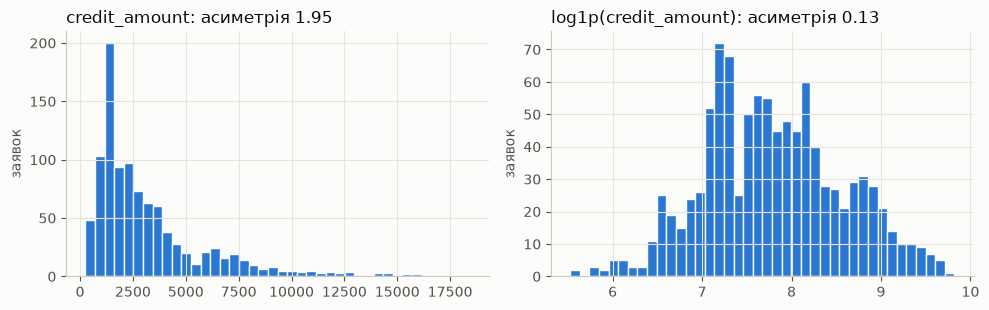

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(clean["credit_amount"], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[0].set_title(f"credit_amount: асиметрія {clean['credit_amount'].skew():.2f}", loc="left")
axes[1].hist(np.log1p(clean["credit_amount"]), bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[1].set_title(f"log1p(credit_amount): асиметрія {np.log1p(clean['credit_amount']).skew():.2f}", loc="left")
for ax in axes: ax.set_ylabel("заявок")
fig.tight_layout(); fig.savefig(FIG / "eda_log1p.png", dpi=130); plt.show()

## 4. Ціль

In [7]:
clean["bad_credit"].value_counts().rename(index={0: "good (0)", 1: "bad (1)"}).to_frame("n").assign(
    share=lambda t: t["n"] / t["n"].sum())

,n,share
bad_credit,,
good (0),700,0.7
bad (1),300,0.3


## 5. 



In [8]:
pd.crosstab(clean["personal_status_sex"], clean["sex"], margins=True)

sex,female,male,All
personal_status_sex,,,
female: divorced/separated/married,310,0,310
male: divorced/separated,0,50,50
male: married/widowed,0,92,92
male: single,0,548,548
All,310,690,1000


In [9]:
by_sex = clean.groupby("sex")["bad_credit"].agg(n="size", bad_rate="mean")
by_sex

,n,bad_rate
sex,,
female,310,0.351613
male,690,0.276812


## 6. Аналіз проксі-ознак



In [10]:
from scipy.stats import chi2_contingency

def cramers_v(a: pd.Series, b: pd.Series) -> float:
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))

cfg = yaml.safe_load((ROOT / "config/config_lr.yaml").read_text(encoding="utf-8"))
candidates = [c for c in clean.columns if c not in ("bad_credit", "sex", "personal_status_sex")]

def as_categories(s: pd.Series) -> pd.Series:
    return pd.qcut(s, 4, duplicates="drop").astype(str) if pd.api.types.is_numeric_dtype(s) and s.nunique() > 6 else s.astype(str)

proxy = pd.DataFrame({
    "V_with_sex": {c: cramers_v(as_categories(clean[c]), clean["sex"]) for c in candidates},
    "V_with_target": {c: cramers_v(as_categories(clean[c]), clean["bad_credit"]) for c in candidates},
}).sort_values("V_with_sex", ascending=False)
proxy["ratio_sex_to_target"] = proxy["V_with_sex"] / proxy["V_with_target"]
proxy.round(3)

,V_with_sex,V_with_target,ratio_sex_to_target
age,0.243,0.119,2.041
housing,0.232,0.135,1.722
employment_since,0.223,0.136,1.645
num_dependents,0.203,0.003,67.476
purpose,0.152,0.183,0.830
installment_rate,0.132,0.074,1.780
credit_history,0.116,0.248,0.467
credit_amount,0.114,0.165,0.691
residence_since,0.109,0.027,3.983
existing_credits,0.103,0.052,1.988


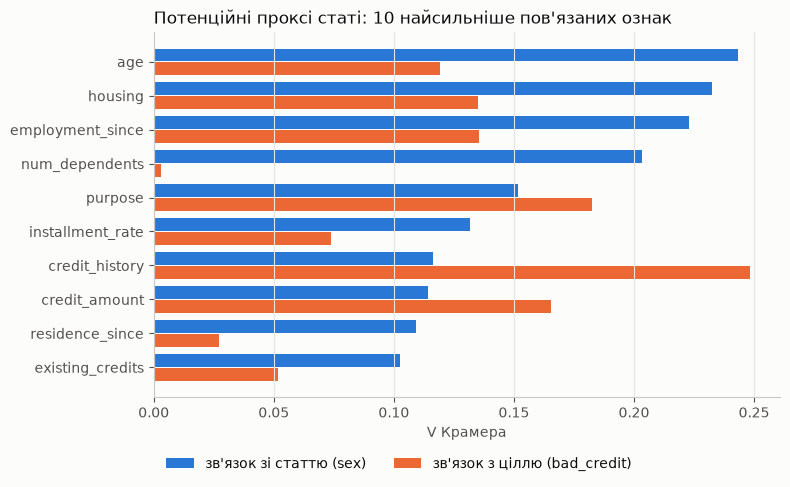

In [11]:
top = proxy.head(10).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(y + 0.2, top["V_with_sex"], height=0.38, color=BLUE, label="зв'язок зі статтю (sex)")
ax.barh(y - 0.2, top["V_with_target"], height=0.38, color=ORANGE, label="зв'язок з ціллю (bad_credit)")
ax.set_yticks(y, top.index); ax.set_xlabel("V Крамера")
ax.set_title("Потенційні проксі статі: 10 найсильніше пов'язаних ознак", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "eda_proxies.png", dpi=130); plt.show()

In [12]:
clean.groupby("sex")["age"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
female,310.0,32.8,11.8,19.0,24.0,29.0,37.0,75.0
male,690.0,36.8,11.0,20.0,28.0,35.0,43.0,75.0


In [13]:
clean.groupby("foreign_worker")["bad_credit"].agg(n="size", bad_rate="mean")

,n,bad_rate
foreign_worker,,
no,37,0.108108
yes,963,0.307373


## 7. Висновки EDA

| Спостереження | Рішення | Де зафіксовано |
|---|---|---|
| `duration`, `credit_amount`, `age` — неперервні з правою асиметрією (1.09 / 1.95 / 1.02) і викидами за IQR | група `numeric_continuous`: `log1p → standard_scaler` для адитивних, `winsorize` для розбиваючих | `transform_policy` |
| `installment_rate`, `residence_since`, `existing_credits` — цілі 1–4 | окрема група `numeric_discrete`: лише шкалювання для адитивних, без перетворень для дерев | `features`, `transform_policy` |
| `employment_since`, `job` мають природний порядок | `categorical_ordinal` з явним порядком рівнів | `ordinal_categories` |
| `checking_account`, `savings_account`, `property` містять рівень «немає/невідомо», що не лежить на шкалі | `categorical_nominal` | `features` |
| Стать закодована разом із сімейним станом; A95 відсутній — для жінок сімейний стан не спостерігається | `sex` (розкодована) і `personal_status_sex` (сире поле) — у `protected_attributes` | `protected_attributes` |
| `foreign_worker`: 96.3% «yes», ознака національного походження | у `protected_attributes`: виключена з моделі, доступна для аудиту | `protected_attributes` |
| `num_dependents`: V зі статтю 0.203, з ціллю 0.003 | **не внесено до `features`** — ризик проксі без користі | коментар у конфігурації |
| `age` (0.243), `housing` (0.232), `employment_since` (0.223) — помітний зв'язок зі статтю, але й власна предиктивна цінність | залишено у `features`; повторна перевірка проксі після першої моделі (ЛР №2–3) | README, п. 5.2 |
